# Sub-Pixel Super-Resolution (ESPCN) with PyTorch

## Develop simple real-time SR convolutional model and assess the quality of its results

## 1. Imports and installation

In [ ]:
# In Google Colab, run this cell if PIQ is not installed yet:
# !pip install -q piq

import os
import math
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from IPython.display import display

SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

## 2. Mount Google Drive and define dataset paths

In [ ]:
# Google Colab only. If running locally, skip this cell and set the paths manually.
try:
    from google.colab import drive
    drive.mount('/content/drive/')
except ImportError:
    print("Google Drive mounting is available only in Colab.")

In [ ]:
!mkdir -p /content/train

In [ ]:
!cp -r "/content/drive/MyDrive/Colab Notebooks/Cats_and_Dogs/train/cats" "/content/train/cats"

In [ ]:
!cp -r "/content/drive/MyDrive/Colab Notebooks/Cats_and_Dogs/val/cats" "/content/val/"

In [ ]:

root_dir = '/content/train/cats'
val_dir = '/content/val'

# The evaluation images are taken from the validation directory, as in the original notebook.
test_path = val_dir

## 3. Hyperparameters and image datasets

In [9]:
crop_size = 300
upscale_factor = 5
input_size = crop_size // upscale_factor
batch_size = 8
num_workers = 2 if os.name != "nt" else 0

IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

class ImageFolderDataset(Dataset):
    def __init__(self, root, image_size, file_list=None):
        self.root = Path(root)
        self.image_size = image_size
        if file_list is None:
            self.paths = sorted(p for p in self.root.rglob('*')
                                if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
        else:
            self.paths = list(file_list)
        if not self.paths:
            raise RuntimeError(f"No images found in: {root}")

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        with Image.open(path) as im:
            im = im.convert('RGB').resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)
            arr = np.asarray(im, dtype=np.float32) / 255.0
        # HWC [0,1] -> CHW float tensor
        return torch.from_numpy(arr).permute(2, 0, 1)

train_full_ds = ImageFolderDataset(root_dir, crop_size)
valid_ds = ImageFolderDataset(val_dir, crop_size)

# use a deterministic 60/40
# split of the training folder, and the separate validation folder for validation.
n_train = max(1, int(0.6 * len(train_full_ds)))
n_unused = len(train_full_ds) - n_train
train_ds, _ = torch.utils.data.random_split(
    train_full_ds, [n_train, n_unused],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers, pin_memory=torch.cuda.is_available())
valid_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False,
                          num_workers=num_workers, pin_memory=torch.cuda.is_available())

print(f"Train images: {len(train_ds)} | Validation images: {len(valid_ds)}")

Train images: 6000 | Validation images: 1240


## 4. Scale images to [0, 1]

Batch shape (B, C, H, W): (8, 3, 300, 300) range: (0.0, 1.0)


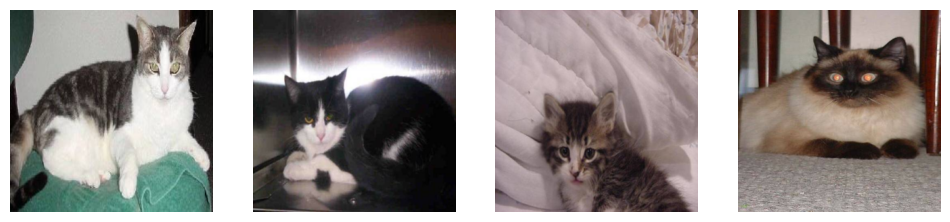

In [10]:
# ImageFolderDataset already converts RGB images to float tensors in [0, 1].
# The following cell displays one batch to verify the input data.
batch = next(iter(train_loader))
print("Batch shape (B, C, H, W):", tuple(batch.shape),
      "range:", (batch.min().item(), batch.max().item()))

fig, axes = plt.subplots(1, min(4, len(batch)), figsize=(12, 3))
for ax, img in zip(np.atleast_1d(axes), batch[:4]):
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.axis('off')
plt.show()

## 5. Test image paths

In [11]:
test_img_paths = sorted(
    str(p) for p in Path(test_path).rglob('*')
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)
print("Number of test images:", len(test_img_paths))
if len(test_img_paths) == 0:
    raise RuntimeError(f"No test images found in {test_path}")

Number of test images: 1240


## 6. Prepare low-resolution input and high-resolution target

In [12]:
def rgb_to_ycbcr_tensor(rgb):
    """Convert RGB tensor (B,3,H,W), range [0,1], to YCbCr-like channels."""
    r, g, b = rgb[:, 0:1], rgb[:, 1:2], rgb[:, 2:3]
    y  = 0.299 * r + 0.587 * g + 0.114 * b
    cb = -0.168736 * r - 0.331264 * g + 0.5 * b + 0.5
    cr =  0.5 * r - 0.418688 * g - 0.081312 * b + 0.5
    return torch.cat([y, cb, cr], dim=1)

def prepare_batch(rgb_batch, input_size, upscale_factor):
    """Return low-resolution Y input and high-resolution Y target."""
    ycbcr = rgb_to_ycbcr_tensor(rgb_batch)
    y = ycbcr[:, 0:1]
    lowres_y = F.interpolate(y, size=(input_size, input_size), mode='area')
    return lowres_y, y

# Transform each RGB batch into (low-resolution luminance, high-resolution luminance).
def sr_collate(batch):
    rgb = torch.stack(batch)
    return prepare_batch(rgb, input_size, upscale_factor)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers, pin_memory=torch.cuda.is_available(), collate_fn=sr_collate)
valid_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False,
                          num_workers=num_workers, pin_memory=torch.cuda.is_available(), collate_fn=sr_collate)

low_y, high_y = next(iter(train_loader))
print("Low-resolution input:", tuple(low_y.shape))
print("High-resolution target:", tuple(high_y.shape))

Low-resolution input: (8, 1, 60, 60)
High-resolution target: (8, 1, 300, 300)


## 7. Visualize input and target

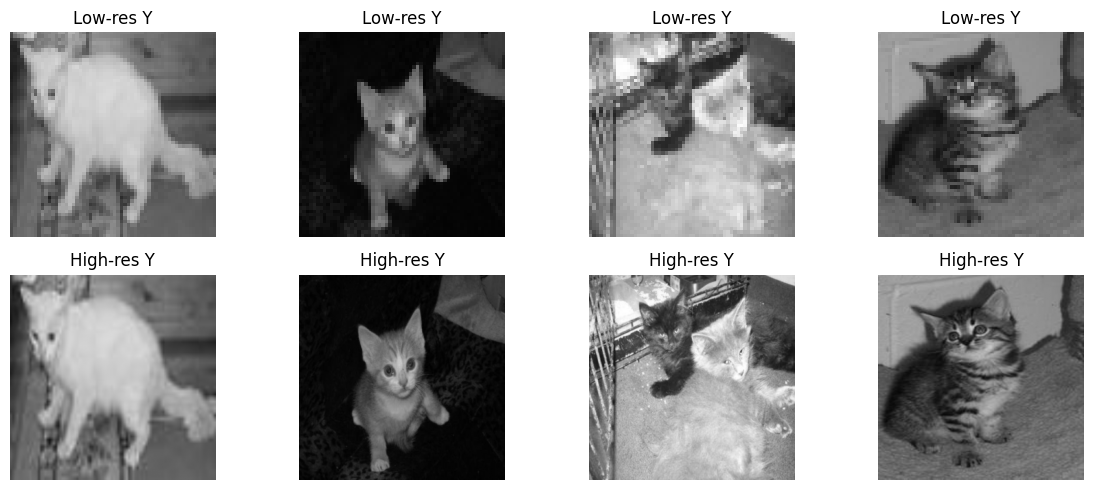

In [13]:
fig, axes = plt.subplots(2, min(4, low_y.shape[0]), figsize=(12, 5))
for i in range(min(4, low_y.shape[0])):
    axes[0, i].imshow(low_y[i, 0].numpy(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title('Low-res Y')
    axes[1, i].imshow(high_y[i, 0].numpy(), cmap='gray', vmin=0, vmax=1)
    axes[1, i].set_title('High-res Y')
    axes[0, i].axis('off'); axes[1, i].axis('off')
plt.tight_layout(); plt.show()

## 8. Define the ESPCN model

In [14]:
class ESPCN(nn.Module):
    """ESPCN-style network: convolutions followed by sub-pixel convolution."""
    def __init__(self, upscale_factor=3, channels=1):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(channels, 64, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, channels * upscale_factor**2, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.pixel_shuffle = nn.PixelShuffle(upscale_factor)

    def forward(self, x):
        return self.pixel_shuffle(self.features(x))


def get_model(upscale_factor=3, channels=1):
    return ESPCN(upscale_factor=upscale_factor, channels=channels)

model = get_model(upscale_factor=upscale_factor, channels=1).to(device)
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

ESPCN(
  (features): Sequential(
    (0): Conv2d(1, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU(inplace=True)
    (6): Conv2d(32, 25, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
  )
  (pixel_shuffle): PixelShuffle(upscale_factor=5)
)
Parameters: 64281


## 9. Plotting, bicubic input and RGB reconstruction

In [15]:
def plot_results(highres_img, bicubic_img, prediction, index, save=True):
    images = [highres_img, bicubic_img, prediction]
    titles = [
        "High-resolution (ground truth)",
        "Bicubic",
        "Model prediction"
    ]

    arrays = [np.asarray(img.convert("RGB")) for img in images]

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    for ax, img, title in zip(axes, arrays, titles):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

        h, w = img.shape[:2]
        x1, x2 = int(w * 0.55), int(w * 0.85)
        y1, y2 = int(h * 0.55), int(h * 0.85)

        axins = ax.inset_axes([0.58, 0.05, 0.38, 0.38])
        axins.imshow(img)
        axins.set_xlim(x1, x2)
        axins.set_ylim(y2, y1)
        axins.set_xticks([])
        axins.set_yticks([])

    fig.suptitle(f"Image {index + 1}: Comparison")
    plt.tight_layout()

    if save:
        plt.savefig(f"comparison-{index + 1}.png", dpi=150)

    plt.show()

In [16]:
def plot_results_old(img, prefix, title):
    """Display an image with a zoomed-in crop and save the figure."""
    if isinstance(img, Image.Image):
        img_array = np.asarray(img)
    else:
        img_array = np.asarray(img)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img_array)
    ax.set_title(title)
    ax.axis('off')
    # Use a central crop so this works for different image sizes.
    h, w = img_array.shape[:2]
    x1, x2 = int(w * 0.55), int(w * 0.85)
    y1, y2 = int(h * 0.55), int(h * 0.85)
    if x2 > x1 and y2 > y1:
        axins = ax.inset_axes([0.58, 0.05, 0.38, 0.38])
        axins.imshow(img_array)
        axins.set_xlim(x1, x2); axins.set_ylim(y2, y1)
        axins.set_xticks([]); axins.set_yticks([])
    plt.tight_layout()
    plt.savefig(f"{prefix}-{title.replace(' ', '_')}.png", dpi=150)
    plt.show()


def get_lowres_image(img, upscale_factor):
    """Downsample RGB PIL image with bicubic interpolation."""
    return img.resize((img.width // upscale_factor, img.height // upscale_factor),
                      Image.Resampling.BICUBIC)


def upscale_image(model, img):
    """Predict luminance, resize chrominance bicubically, and return RGB PIL image."""
    ycbcr = img.convert('YCbCr')
    y, cb, cr = ycbcr.split()
    y_arr = np.asarray(y, dtype=np.float32) / 255.0
    x = torch.from_numpy(y_arr)[None, None].to(device)
    model.eval()
    with torch.no_grad():
        pred_y = model(x).clamp(0, 1)[0, 0].cpu().numpy()
    out_y = Image.fromarray(np.uint8(np.round(pred_y * 255.0)), mode='L')
    out_cb = cb.resize(out_y.size, Image.Resampling.BICUBIC)
    out_cr = cr.resize(out_y.size, Image.Resampling.BICUBIC)
    return Image.merge('YCbCr', (out_y, out_cb, out_cr)).convert('RGB')


def psnr_from_mse(mse):
    return 10.0 * math.log10(1.0 / max(float(mse), 1e-12))

## 10. Training callback equivalent: validation PSNR and sample predictions

In [17]:
def evaluate_epoch_psnr(model, loader):
    model.eval()
    values = []
    with torch.no_grad():
        for x, target in loader:
            x, target = x.to(device), target.to(device)
            pred = model(x).clamp(0, 1)
            mse = F.mse_loss(pred, target).item()
            values.append(psnr_from_mse(mse))
    return float(np.mean(values)) if values else float('nan')

# A fixed sample image for periodic qualitative inspection.
callback_test_index = min(12, len(test_img_paths) - 1)
callback_test_img = get_lowres_image(Image.open(test_img_paths[callback_test_index]).convert('RGB'), upscale_factor)

## 11. Callbacks, checkpoint and optimizer

In [18]:
checkpoint_dir = Path('/tmp/checkpoint')
checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_filepath = checkpoint_dir / 'sr_pytorch.pt'

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
early_stopping_patience = 10
best_val_loss = float('inf')
epochs_without_improvement = 0
history = {'train_loss': [], 'val_loss': [], 'val_psnr': []}

## 12. Train the model

Epoch 01/20 | train loss: 0.006141 | val loss: 0.001797 | val PSNR: 27.64 dB


/tmp/ipykernel_492/3369600816.py:40: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  out_y = Image.fromarray(np.uint8(np.round(pred_y * 255.0)), mode='L')


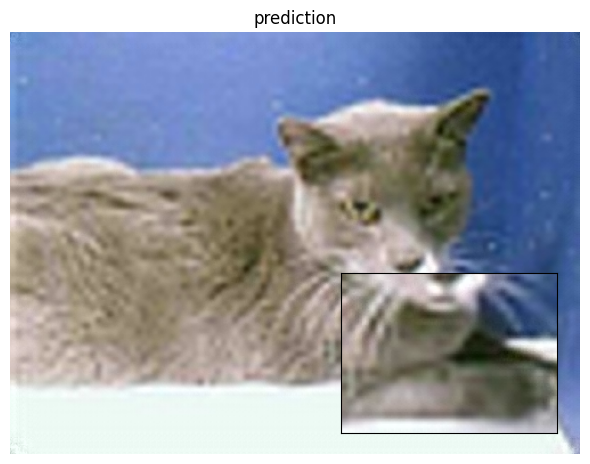

Epoch 02/20 | train loss: 0.001740 | val loss: 0.001720 | val PSNR: 27.84 dB
Epoch 03/20 | train loss: 0.001731 | val loss: 0.001681 | val PSNR: 27.94 dB
Epoch 04/20 | train loss: 0.001664 | val loss: 0.001648 | val PSNR: 28.02 dB
Epoch 05/20 | train loss: 0.001652 | val loss: 0.001640 | val PSNR: 28.05 dB
Epoch 06/20 | train loss: 0.001622 | val loss: 0.001660 | val PSNR: 27.98 dB


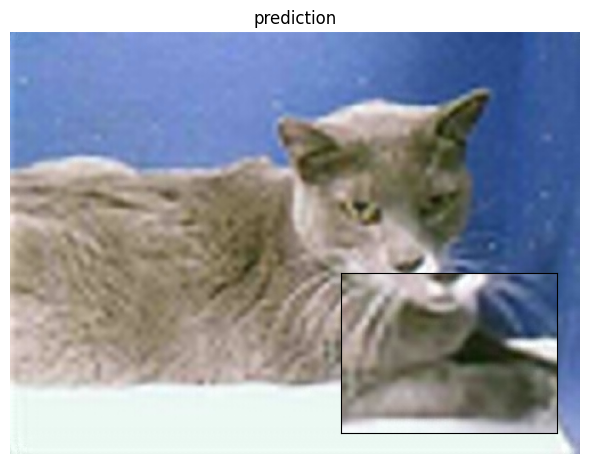

Epoch 07/20 | train loss: 0.001585 | val loss: 0.001595 | val PSNR: 28.17 dB
Epoch 08/20 | train loss: 0.001571 | val loss: 0.001601 | val PSNR: 28.15 dB
Epoch 09/20 | train loss: 0.001560 | val loss: 0.001610 | val PSNR: 28.13 dB
Epoch 10/20 | train loss: 0.001554 | val loss: 0.001570 | val PSNR: 28.24 dB
Epoch 11/20 | train loss: 0.001525 | val loss: 0.001561 | val PSNR: 28.26 dB


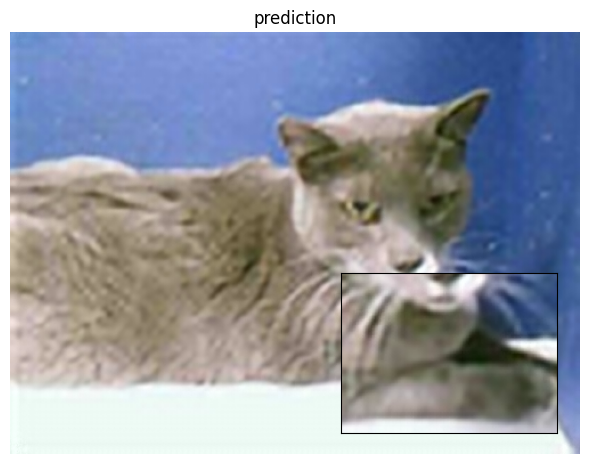

Epoch 12/20 | train loss: 0.001529 | val loss: 0.001534 | val PSNR: 28.34 dB
Epoch 13/20 | train loss: 0.001514 | val loss: 0.001527 | val PSNR: 28.36 dB
Epoch 14/20 | train loss: 0.001510 | val loss: 0.001528 | val PSNR: 28.36 dB
Epoch 15/20 | train loss: 0.001502 | val loss: 0.001517 | val PSNR: 28.39 dB
Epoch 16/20 | train loss: 0.001485 | val loss: 0.001537 | val PSNR: 28.32 dB


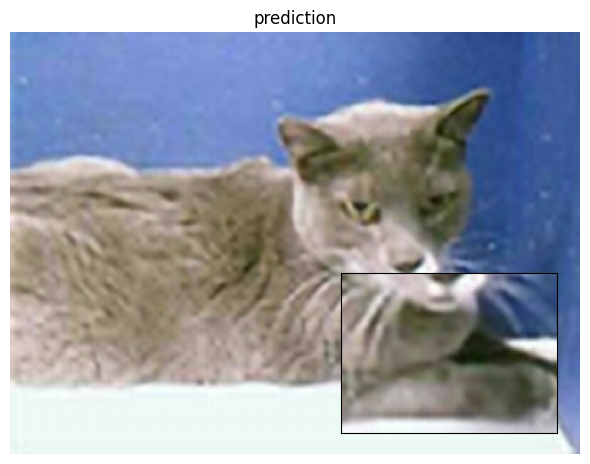

Epoch 17/20 | train loss: 0.001486 | val loss: 0.001503 | val PSNR: 28.43 dB
Epoch 18/20 | train loss: 0.001472 | val loss: 0.001503 | val PSNR: 28.43 dB
Epoch 19/20 | train loss: 0.001477 | val loss: 0.001494 | val PSNR: 28.45 dB
Epoch 20/20 | train loss: 0.001469 | val loss: 0.001497 | val PSNR: 28.44 dB
Loaded best checkpoint from epoch 19 (val loss=0.001494).


In [19]:
epochs = 20

for epoch in range(1, epochs + 1):
    model.train()
    train_losses = []
    for lowres_y, highres_y in train_loader:
        lowres_y = lowres_y.to(device, non_blocking=True)
        highres_y = highres_y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        prediction = model(lowres_y)
        loss = loss_fn(prediction, highres_y)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    model.eval()
    val_losses = []
    with torch.no_grad():
        for lowres_y, highres_y in valid_loader:
            lowres_y = lowres_y.to(device, non_blocking=True)
            highres_y = highres_y.to(device, non_blocking=True)
            val_losses.append(loss_fn(model(lowres_y), highres_y).item())

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))
    val_psnr = evaluate_epoch_psnr(model, valid_loader)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_psnr'].append(val_psnr)
    print(f"Epoch {epoch:02d}/{epochs} | train loss: {train_loss:.6f} | "
          f"val loss: {val_loss:.6f} | val PSNR: {val_psnr:.2f} dB")

    # Save the best checkpoint based on validation loss.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save({'model_state_dict': model.state_dict(),
                    'upscale_factor': upscale_factor,
                    'epoch': epoch,
                    'val_loss': val_loss}, checkpoint_filepath)
    else:
        epochs_without_improvement += 1

    if epoch % 5 == 1:
        sample_prediction = upscale_image(model, callback_test_img)
        plot_results_old(sample_prediction, f'epoch-{epoch}', 'prediction')

    if epochs_without_improvement >= early_stopping_patience:
        print(f"Early stopping: no validation improvement for {early_stopping_patience} epochs.")
        break

# Restore the best validation checkpoint.
checkpoint = torch.load(checkpoint_filepath, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Loaded best checkpoint from epoch {checkpoint['epoch']} (val loss={checkpoint['val_loss']:.6f}).")

## 13. Training curves

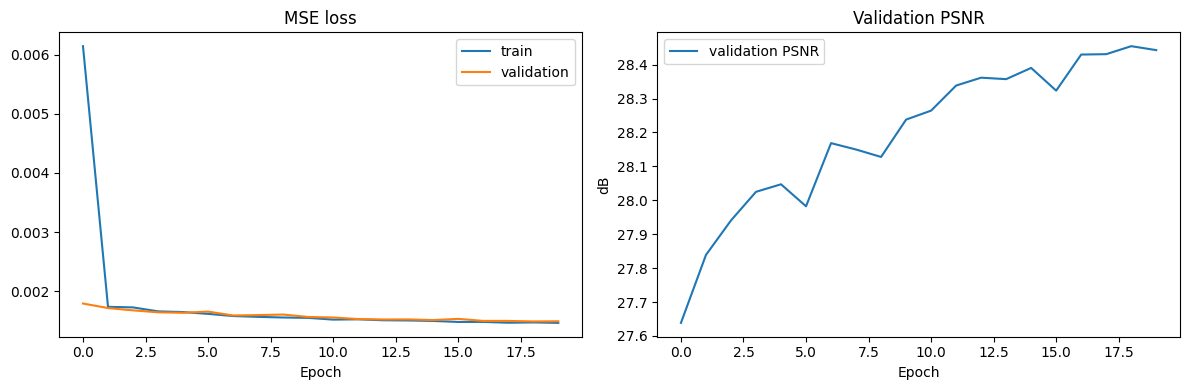

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='validation')
axes[0].set_title('MSE loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history['val_psnr'], label='validation PSNR')
axes[1].set_title('Validation PSNR'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('dB'); axes[1].legend()
plt.tight_layout(); plt.show()

## 14. Initialize PIQ image-quality metrics

In [21]:
!pip install piq

In [22]:
# Install once if needed:
# !pip install -q piq
from piq import BRISQUELoss, DISTS, ssim, psnr

brisque_metric = BRISQUELoss(data_range=1.).to(device).eval()
dists_metric = DISTS().to(device).eval()

# PIQ expects RGB tensors in NCHW format, with values in [0, 1].
def pil_to_metric_tensor(img):
    arr = np.asarray(img.convert('RGB'), dtype=np.float32) / 255.0
    return torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(device)

Downloading: "https://github.com/photosynthesis-team/piq/releases/download/v0.4.1/dists_weights.pt" to /root/.cache/torch/hub/checkpoints/dists_weights.pt


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


## 15. Evaluate bicubic interpolation and model predictions

/tmp/ipykernel_492/3369600816.py:40: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  out_y = Image.fromarray(np.uint8(np.round(pred_y * 255.0)), mode='L')


Downloading: "https://github.com/photosynthesis-team/piq/releases/download/v0.4.0/brisque_svm_weights.pt" to /root/.cache/torch/hub/checkpoints/brisque_svm_weights.pt


100%|██████████| 112k/112k [00:00<00:00, 27.3MB/s]



Image 1: cat.11310.jpg
PSNR:   bicubic=34.614 | model=35.367
SSIM:   bicubic=0.9059 | model=0.9170
BRISQUE bicubic=69.663 | model=59.167 | HR=30.892
DISTS:  bicubic=0.1679 | model=0.1349


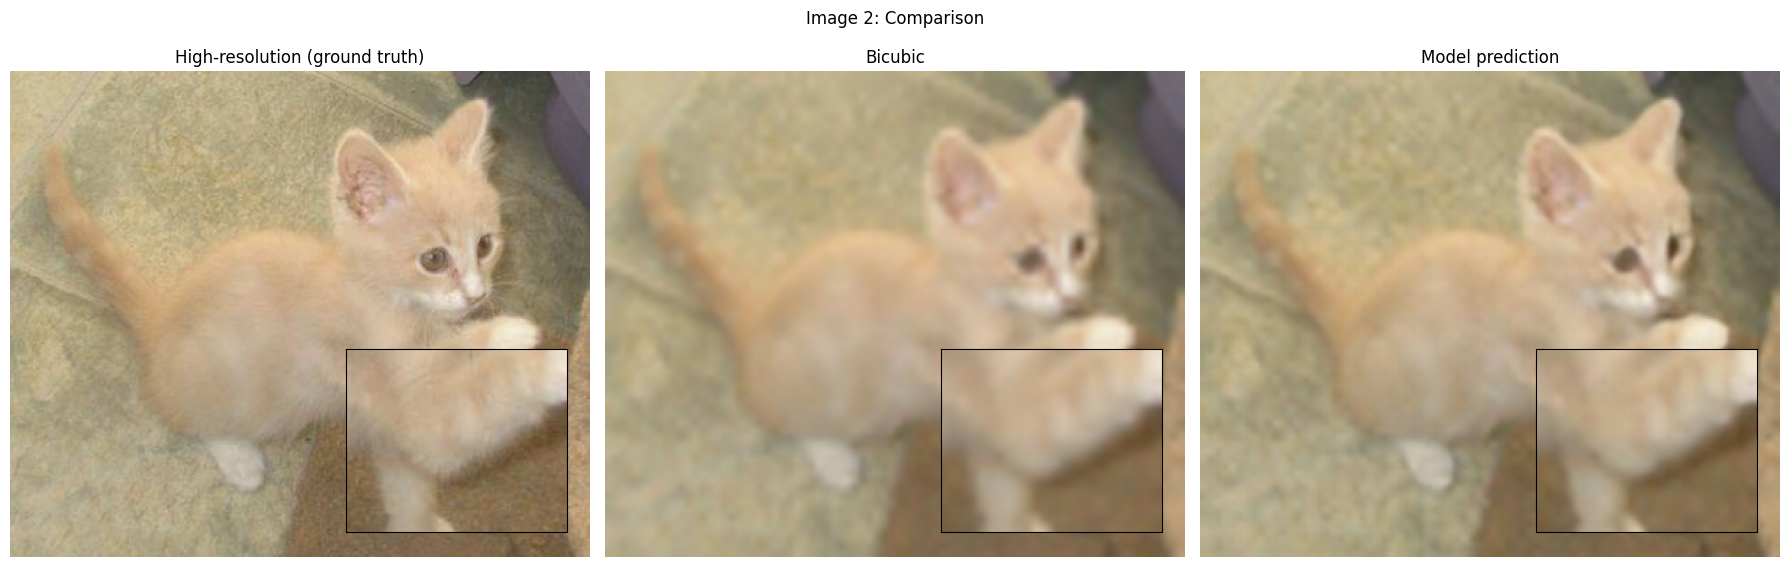


Image 2: cat.11311.jpg
PSNR:   bicubic=34.208 | model=34.216
SSIM:   bicubic=0.8255 | model=0.8315
BRISQUE bicubic=70.092 | model=57.563 | HR=13.649
DISTS:  bicubic=0.1982 | model=0.1773

Image 3: cat.11312.jpg
PSNR:   bicubic=37.967 | model=38.568
SSIM:   bicubic=0.9664 | model=0.9674
BRISQUE bicubic=77.925 | model=69.069 | HR=51.599
DISTS:  bicubic=0.1011 | model=0.0759

Image 4: cat.11313.jpg
PSNR:   bicubic=27.352 | model=27.996
SSIM:   bicubic=0.7627 | model=0.7835
BRISQUE bicubic=67.547 | model=54.439 | HR=2.568
DISTS:  bicubic=0.2130 | model=0.2047

Image 5: cat.11314.jpg
PSNR:   bicubic=27.549 | model=28.184
SSIM:   bicubic=0.7063 | model=0.7364
BRISQUE bicubic=69.060 | model=61.027 | HR=19.192
DISTS:  bicubic=0.2683 | model=0.2428


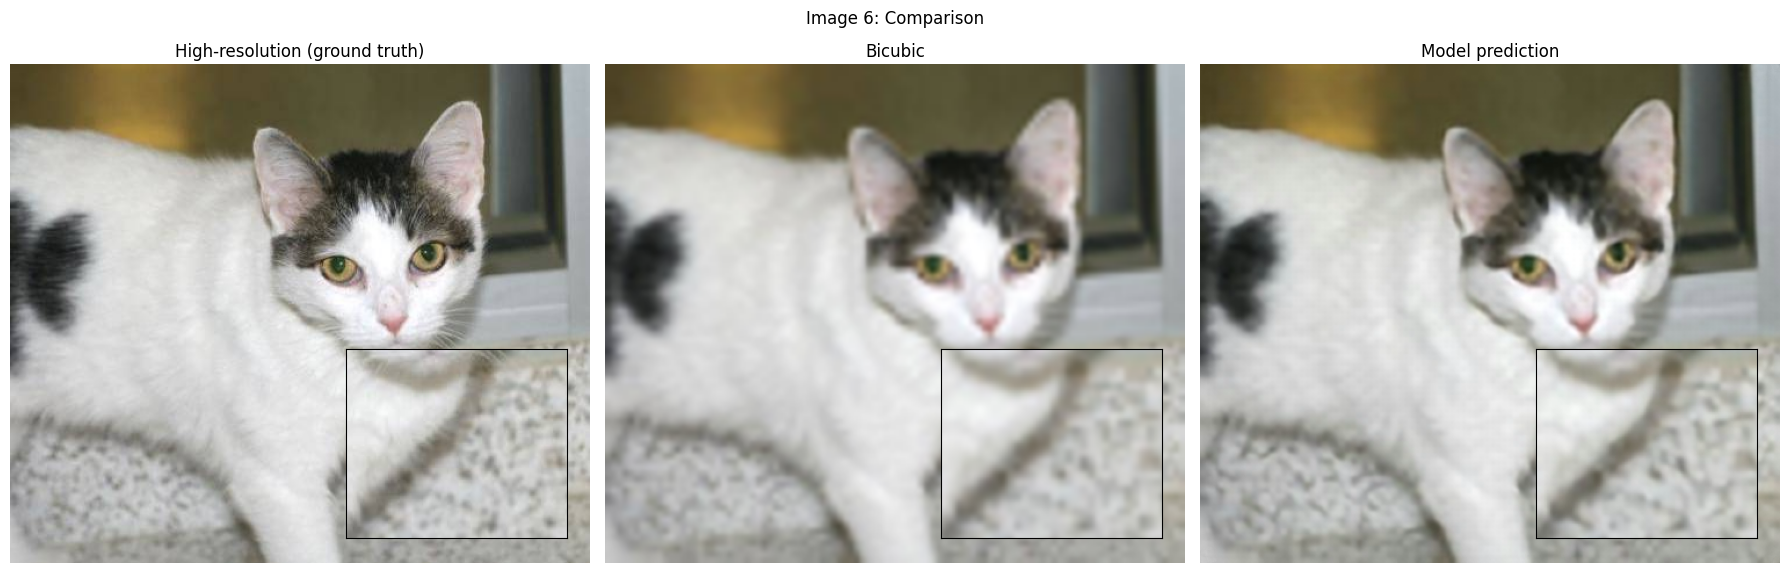


Image 6: cat.11315.jpg
PSNR:   bicubic=32.551 | model=33.712
SSIM:   bicubic=0.9320 | model=0.9488
BRISQUE bicubic=69.065 | model=53.455 | HR=36.321
DISTS:  bicubic=0.1417 | model=0.1114


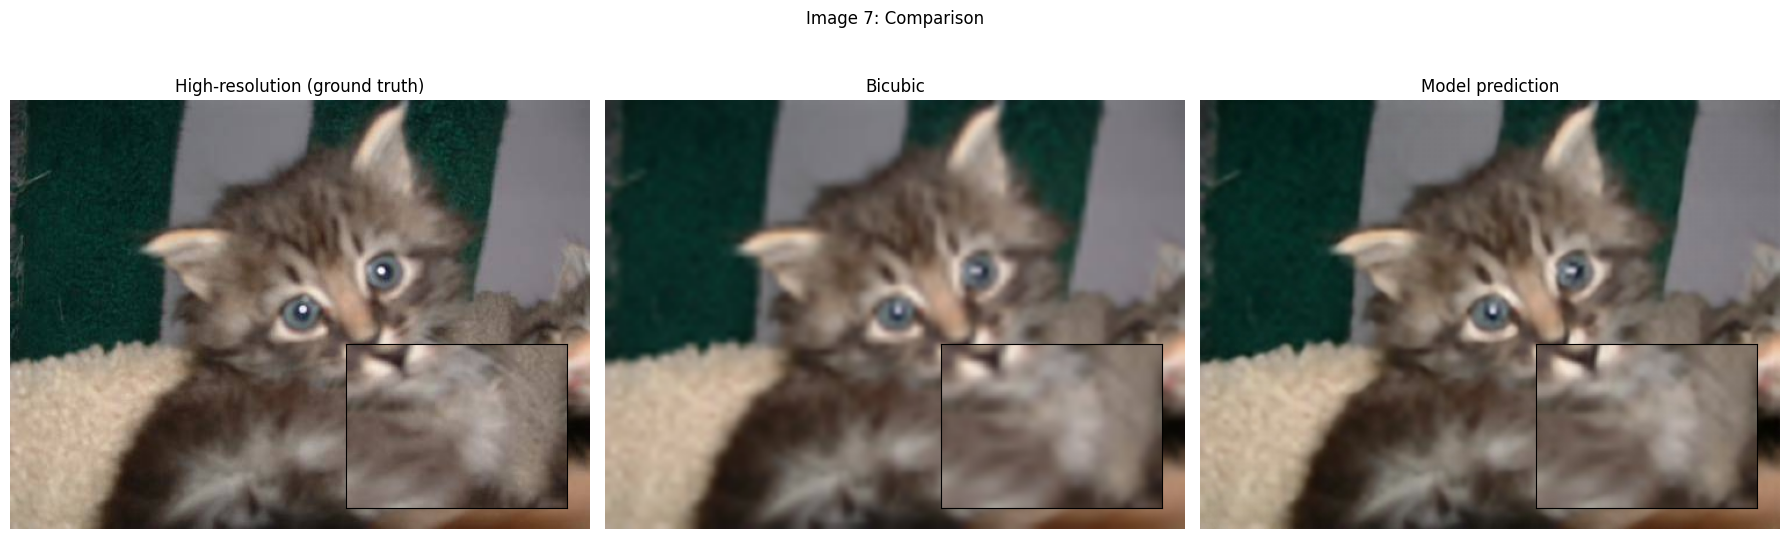


Image 7: cat.11316.jpg
PSNR:   bicubic=35.392 | model=35.886
SSIM:   bicubic=0.9206 | model=0.9254
BRISQUE bicubic=71.888 | model=61.274 | HR=29.736
DISTS:  bicubic=0.1068 | model=0.0807

Image 8: cat.11317.jpg
PSNR:   bicubic=28.374 | model=29.299
SSIM:   bicubic=0.7946 | model=0.8207
BRISQUE bicubic=72.335 | model=60.462 | HR=29.758
DISTS:  bicubic=0.2553 | model=0.2135


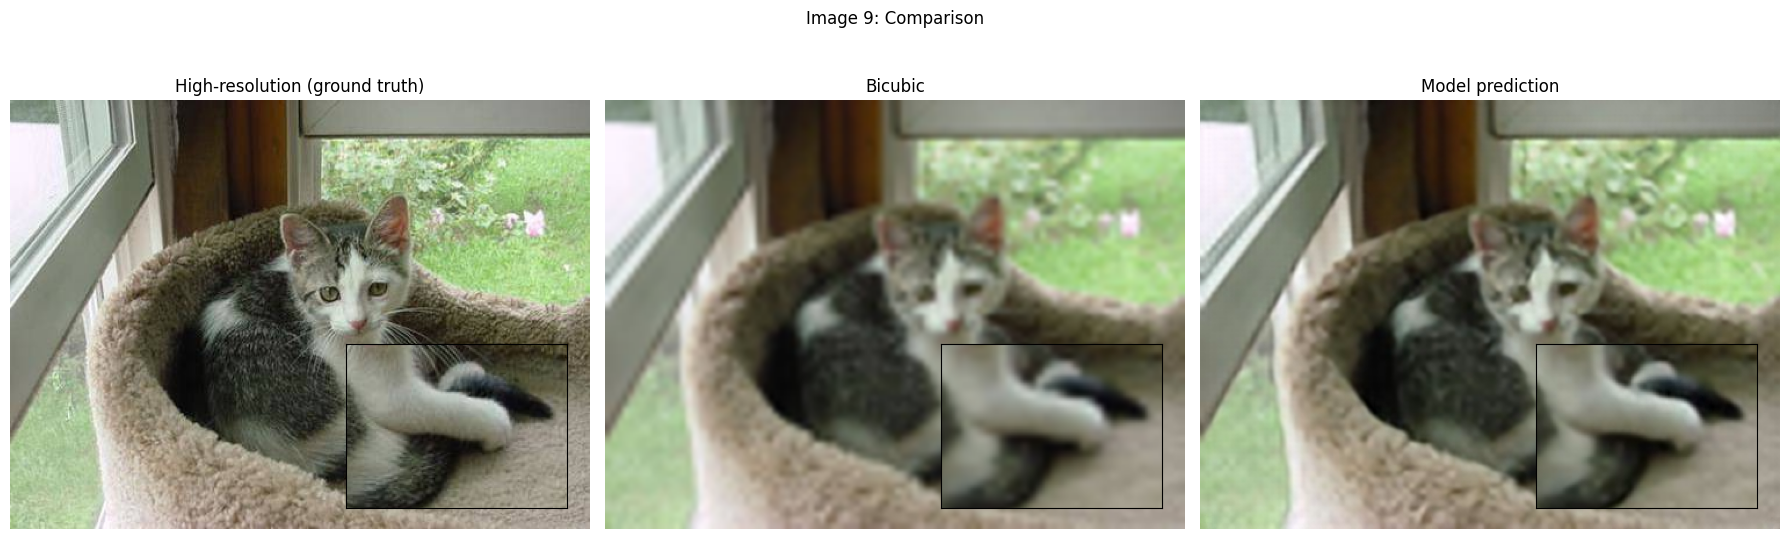


Image 9: cat.11318.jpg
PSNR:   bicubic=26.298 | model=26.858
SSIM:   bicubic=0.6216 | model=0.6523
BRISQUE bicubic=68.673 | model=58.358 | HR=14.841
DISTS:  bicubic=0.2025 | model=0.1830


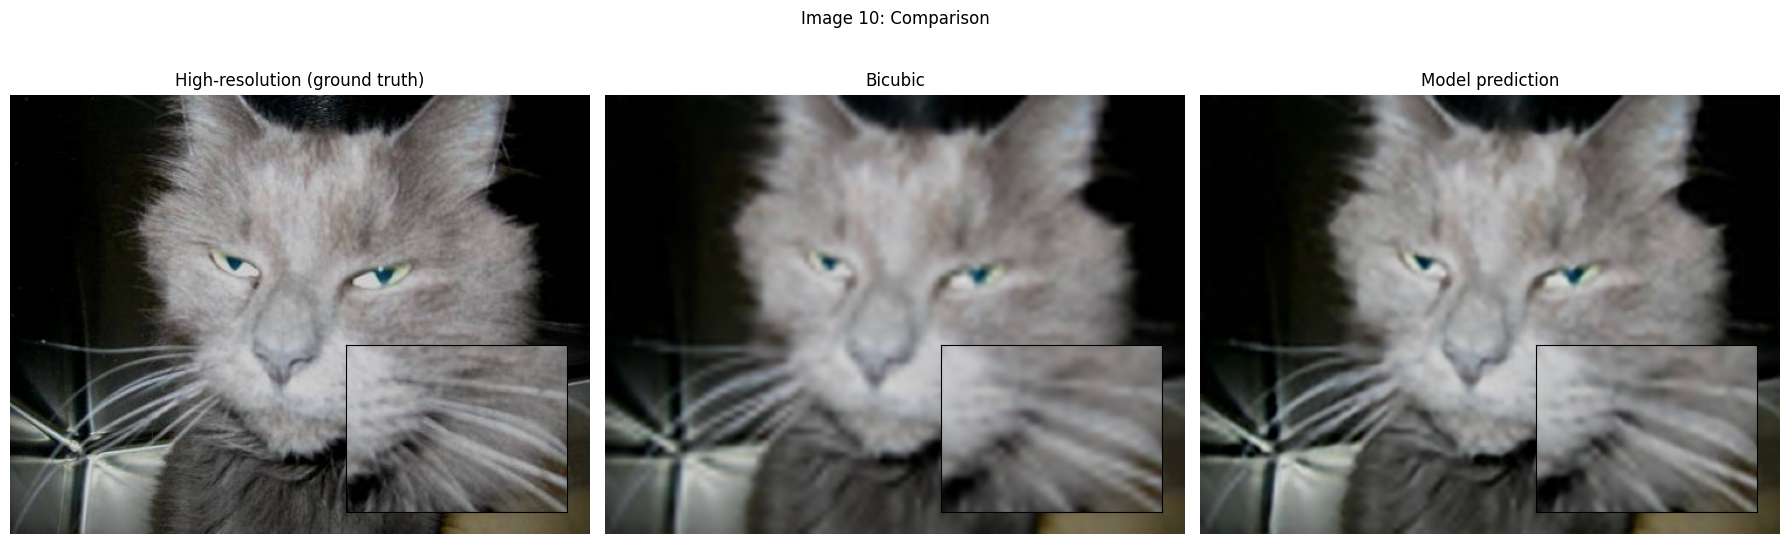


Image 10: cat.11319.jpg
PSNR:   bicubic=29.446 | model=30.710
SSIM:   bicubic=0.8122 | model=0.8290
BRISQUE bicubic=72.789 | model=57.283 | HR=25.690
DISTS:  bicubic=0.1482 | model=0.1230
-------------------------------------------------------
Average metrics over 10 images
PSNR   | bicubic: 31.375 | model: 32.080
SSIM   | bicubic: 0.8248 | model: 0.8412
BRISQUE| bicubic: 70.904 | model: 59.210 | HR: 25.425
DISTS  | bicubic: 0.1803 | model: 0.1547


In [23]:
total_bicubic_psnr = 0.0
total_test_psnr = 0.0
total_bicubic_ssim = 0.0
total_test_ssim = 0.0
total_bicubic_brisque = 0.0
total_test_brisque = 0.0
total_highres_brisque = 0.0
total_bicubic_dists = 0.0
total_test_dists = 0.0

start_index = 60
n_requested = 10
selected_test_paths = test_img_paths[start_index:start_index + n_requested]
n_evaluated = len(selected_test_paths)
if n_evaluated == 0:
    raise RuntimeError(f"No evaluation images in test_img_paths[{start_index}:{start_index+n_requested}].")

for index, test_img_path in enumerate(selected_test_paths):
    img = Image.open(test_img_path).convert('RGB')
    lowres_input = get_lowres_image(img, upscale_factor)
    w, h = lowres_input.width * upscale_factor, lowres_input.height * upscale_factor

    # Match the dimensions exactly in case the source dimensions are not divisible by scale.
    highres_img = img.resize((w, h), Image.Resampling.BICUBIC)
    prediction = upscale_image(model, lowres_input)
    bicubic_img = lowres_input.resize((w, h), Image.Resampling.BICUBIC)

    torch_lr = pil_to_metric_tensor(bicubic_img)
    torch_hr = pil_to_metric_tensor(highres_img)
    torch_predict = pil_to_metric_tensor(prediction)

    with torch.no_grad():
        bicubic_psnr = psnr(torch_lr, torch_hr, data_range=1.).item()
        test_psnr = psnr(torch_predict, torch_hr, data_range=1.).item()
        bicubic_ssim = ssim(torch_lr, torch_hr, data_range=1.).item()
        test_ssim = ssim(torch_predict, torch_hr, data_range=1.).item()

        # BRISQUE is a no-reference metric. These scores describe each image individually;
        # the HR image is included as a reference point, not as a pairwise comparison.
        bicubic_brisque = brisque_metric(torch_lr).item()
        highres_brisque = brisque_metric(torch_hr).item()
        test_brisque = brisque_metric(torch_predict).item()

        bicubic_dists = dists_metric(torch_lr, torch_hr).item()
        test_dists = dists_metric(torch_predict, torch_hr).item()

    total_bicubic_psnr += bicubic_psnr
    total_test_psnr += test_psnr
    total_bicubic_ssim += bicubic_ssim
    total_test_ssim += test_ssim
    total_bicubic_brisque += bicubic_brisque
    total_test_brisque += test_brisque
    total_highres_brisque += highres_brisque
    total_bicubic_dists += bicubic_dists
    total_test_dists += test_dists

    if w > 300 and h > 300:
      plot_results(highres_img, bicubic_img, prediction, index)

    print(f"\nImage {index + 1}: {Path(test_img_path).name}")
    print(f"PSNR:   bicubic={bicubic_psnr:.3f} | model={test_psnr:.3f}")
    print(f"SSIM:   bicubic={bicubic_ssim:.4f} | model={test_ssim:.4f}")
    print(f"BRISQUE bicubic={bicubic_brisque:.3f} | model={test_brisque:.3f} | HR={highres_brisque:.3f}")
    print(f"DISTS:  bicubic={bicubic_dists:.4f} | model={test_dists:.4f}")

print('-' * 55)
print('Average metrics over', n_evaluated, 'images')
print(f"PSNR   | bicubic: {total_bicubic_psnr/n_evaluated:.3f} | model: {total_test_psnr/n_evaluated:.3f}")
print(f"SSIM   | bicubic: {total_bicubic_ssim/n_evaluated:.4f} | model: {total_test_ssim/n_evaluated:.4f}")
print(f"BRISQUE| bicubic: {total_bicubic_brisque/n_evaluated:.3f} | model: {total_test_brisque/n_evaluated:.3f} | HR: {total_highres_brisque/n_evaluated:.3f}")
print(f"DISTS  | bicubic: {total_bicubic_dists/n_evaluated:.4f} | model: {total_test_dists/n_evaluated:.4f}")

/tmp/ipykernel_492/3369600816.py:40: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  out_y = Image.fromarray(np.uint8(np.round(pred_y * 255.0)), mode='L')


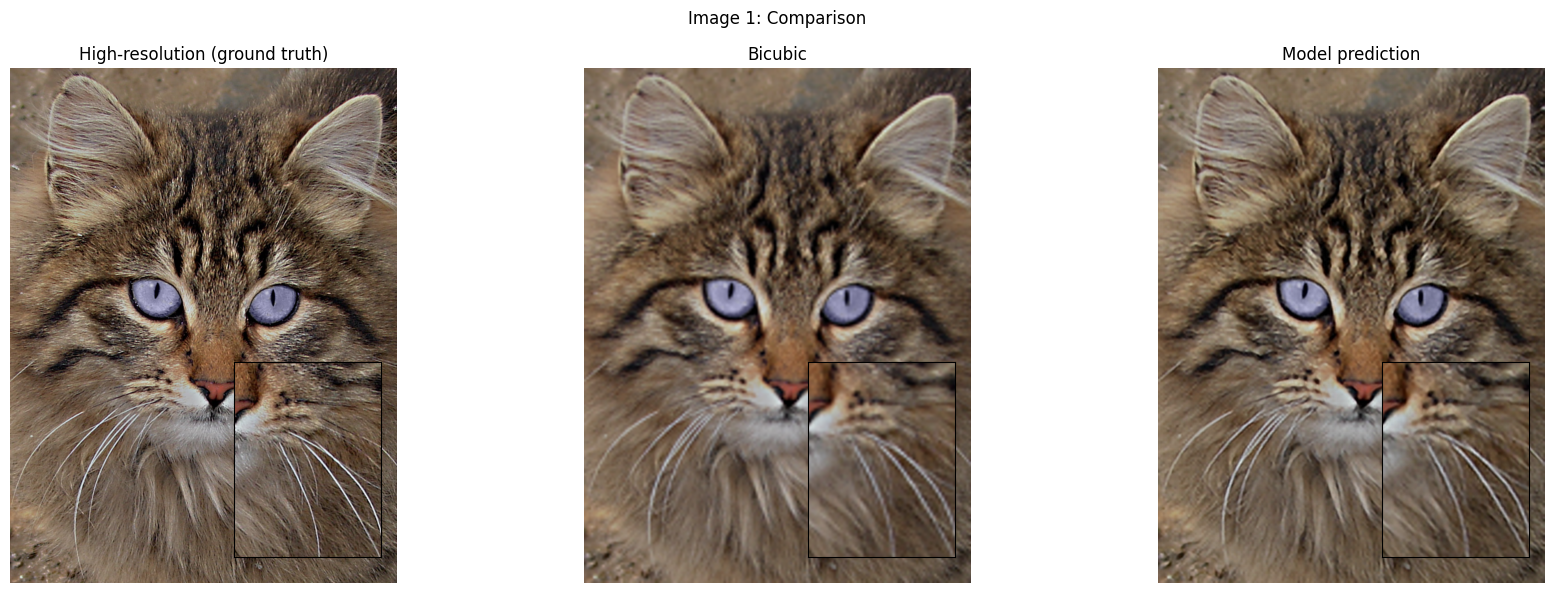

In [24]:
selected_test_paths = ['/content/drive/My Drive/Cat_07464_kalamis_safinaz.jpg']

for index, test_img_path in enumerate(selected_test_paths):
    img = Image.open(test_img_path).convert('RGB')
    lowres_input = get_lowres_image(img, upscale_factor)
    w, h = lowres_input.width * upscale_factor, lowres_input.height * upscale_factor

    # Match the dimensions exactly in case the source dimensions are not divisible by scale.
    highres_img = img.resize((w, h), Image.Resampling.BICUBIC)
    prediction = upscale_image(model, lowres_input)
    bicubic_img = lowres_input.resize((w, h), Image.Resampling.BICUBIC)

    if w > 300 and h > 300:
      plot_results(highres_img, bicubic_img, prediction, index)